In [6]:
import os
from matplotlib import pyplot as plt
from astropy.table import Table
import numpy as np

In [7]:
files = os.listdir('../output/tables/')
catalog = []
for file in files:
    if "table" in file:
        catalog.append(file.split('table_')[1].split('.tbl')[0])
print(catalog)

['glimpse2_v2cat', 'glimpse360c', 'glimpse3d_v1cat_tbl', 'glimpse_s07', 'glimpse_s07_ar']


In [8]:
data = []
for cat in catalog:
    cat_table = Table.read('../output/tables/match_table_'+cat+'.tbl',format='ipac')
    data.append(len(cat_table))

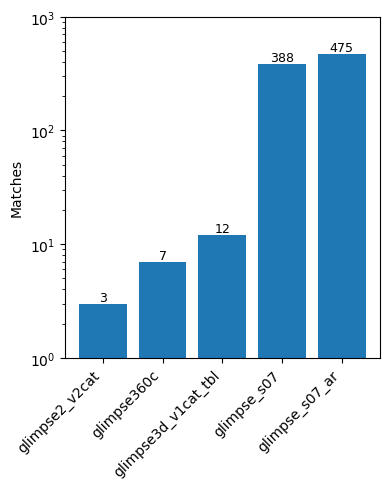

In [9]:
x = np.arange(len(data))

fig, ax = plt.subplots(figsize=(4,5),tight_layout=True)
fig.subplots_adjust(bottom=0.25)
bars = ax.bar(x, data)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(catalog, rotation=45, ha="right", fontsize=10)
ax.set_ylim(1,1000)
#ax.set_title("Catalog match comparison")
ax.set_ylabel("Matches")
ax.set_yscale("log")

plt.savefig('../output/figures/catalog_comparison.pdf',format='pdf')
plt.show()